# Notebook 04 — Comparação entre medidas de relevância de atributos

Este notebook estima a relevância dos atributos por três métodos e compara os resultados:

| Método | O que mede |
| --- | --- |
| Regressão linear | Quanto o poder explicativo do modelo (R²) diminui quando o atributo é retirado, mantidos os demais |
| RReliefF | Se estudantes parecidos nos demais atributos, mas diferentes neste, também diferem na proficiência |
| Random Forest | Quanto o desempenho do modelo em estudantes de teste piora quando a informação do atributo é embaralhada |

As três medidas respondem a perguntas diferentes. A comparação é feita pelo significado de cada uma, e as divergências são examinadas, e não descartadas.


**Entrada:** `base_analitica.parquet`. **Saídas:** `tabelas_comparacao_metodos.xlsx`, `particao_treino_teste.csv`, `figura_comparacao_metodos.png`.



## 0. Configuração

In [15]:
import sys, time, numpy as np, pandas as pd
import sklearn, statsmodels, statsmodels.formula.api as smf
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupShuffleSplit, train_test_split, GroupKFold
from sklearn.metrics import r2_score, mean_squared_error
from scipy.stats import spearmanr
import matplotlib, matplotlib.pyplot as plt
import warnings; warnings.filterwarnings('ignore')

try:
    from google.colab import drive
    drive.mount('/content/drive')
    PASTA = '/content/drive/MyDrive/dissertacao/'   # ajuste para a sua pasta
except ImportError:
    PASTA = './'

SEMENTE = 2025          # semente única, usada em todas as etapas aleatórias
FATOR_SAEB = 55.093
print({'python': sys.version.split()[0], 'pandas': pd.__version__, 'numpy': np.__version__,
       'scikit-learn': sklearn.__version__, 'statsmodels': statsmodels.__version__, 'semente': SEMENTE})

base = pd.read_parquet(PASTA + 'base_analitica.parquet').reset_index(drop=True)
assert len(base) == 22996
y = base['proficiencia'].values
TABELAS = {}

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
{'python': '3.13.16', 'pandas': '2.2.3', 'numpy': '2.1.3', 'scikit-learn': '1.6.1', 'statsmodels': '0.15.0', 'semente': 2025}


## 1. Atributos e critério de convergência

**Atributos comparados.** Os mesmos 20 atributos nos três métodos. Sexo, raça/cor e pretensão futura são tratados como um único atributo nominal cada um (e não como várias colunas separadas), para que todos os atributos sejam comparados na mesma unidade.

**Controles.** Os três métodos recebem também as variáveis de controle do modelo principal (modalidade, indicadores de "não sei" e de resposta ausente e número de itens sem resposta). Elas participam dos modelos, mas não entram nos rankings.


In [16]:
NOMINAIS = {'sexo': 'Sexo', 'raca_cor': 'Raça/cor', 'pretensao_futura': 'Pretensão futura'}
NUMERICOS = {'idade': 'Idade', 'reprovacao': 'Reprovação',
             'aluno_motivacao_aplicar_aprendizado': 'Q23b (motivação para usar o que foi ensinado)',
             'tempo_estudos': 'Tempo de estudos', 'tempo_cursos': 'Tempo em cursos',
             'tempo_trabalho_domestico': 'Trabalho doméstico', 'tempo_trabalho': 'Trabalho fora de casa',
             'mora_mae': 'Mora com a mãe', 'mora_pai': 'Mora com o pai',
             'escolaridade_mae': 'Escolaridade da mãe', 'escolaridade_pai': 'Escolaridade do pai',
             'responsaveis_incentivam_estudo': 'Responsáveis incentivam o estudo',
             'responsaveis_conversam_escola': 'Responsáveis conversam sobre a escola',
             'qtd_computadores': 'Computadores', 'possui_wifi': 'Wi-Fi',
             'possui_escrivaninha': 'Mesa para estudar', 'possui_casa_quarto_individual': 'Quarto só seu'}
ATRIBUTOS = {**NOMINAIS, **NUMERICOS}
CONTROLES = ['em_integrado', 'nao_sabe_escolaridade_mae', 'nao_sabe_escolaridade_pai',
             'ausente_escolaridade_mae', 'ausente_escolaridade_pai',
             'ausente_aluno_motivacao_aplicar_aprendizado', 'ausente_mora_mae', 'ausente_mora_pai',
             'n_itens_ausentes']
REF = {'sexo': 'Masculino', 'raca_cor': 'Branca', 'pretensao_futura': 'Somente estudar'}
TOP = 5
print(len(ATRIBUTOS), 'atributos comparados |', len(CONTROLES), 'controles')

20 atributos comparados | 9 controles


## 2. Regressão: contribuição de cada atributo

Para cada atributo, o modelo principal é reestimado sem ele, e registra-se a redução do R² (contribuição exclusiva do atributo). Nos atributos nominais, todas as categorias são retiradas juntas. A significância é dada pelo teste conjunto (Wald) dos coeficientes do atributo, com erros-padrão agrupados por escola.

In [17]:
def termo(v):
    return f"C({v}, Treatment({REF[v]!r}))" if v in NOMINAIS else v

def formula(atribs):
    return 'proficiencia ~ ' + ' + '.join([termo(v) for v in atribs] + CONTROLES)

completo = smf.ols(formula(ATRIBUTOS), base).fit(cov_type='cluster', cov_kwds={'groups': base['id_escola']}, use_t=True)
nomes = list(completo.params.index)
linhas = []
for v, rot in ATRIBUTOS.items():
    sem = smf.ols(formula([a for a in ATRIBUTOS if a != v]), base).fit()
    cols = [i for i, n in enumerate(nomes) if n == v or n.startswith(termo(v) + '[')]
    R = np.zeros((len(cols), len(nomes)))
    for r_, c_ in enumerate(cols): R[r_, c_] = 1
    p = float(completo.wald_test(R, scalar=True).pvalue)
    linhas.append({'var': v, 'Atributo': rot, 'Redução do R²': completo.rsquared - sem.rsquared, 'p (Wald)': p})
reg = pd.DataFrame(linhas)
reg['Relevante (regressão)'] = reg['p (Wald)'] < 0.05
reg['Posição (regressão)'] = reg['Redução do R²'].rank(ascending=False).astype(int)
TABELAS['Ranking regressão'] = reg.sort_values('Posição (regressão)').drop(columns='var').round(6)
print(f'R² do modelo completo: {completo.rsquared:.4f}')
print(reg.sort_values('Posição (regressão)')[['Atributo', 'Redução do R²', 'p (Wald)', 'Posição (regressão)']]
      .to_string(index=False, formatters={'Redução do R²': '{:.5f}'.format, 'p (Wald)': '{:.2e}'.format}))

R² do modelo completo: 0.2092
                                     Atributo Redução do R² p (Wald)  Posição (regressão)
Q23b (motivação para usar o que foi ensinado)       0.02641 1.38e-75                    1
                             Pretensão futura       0.01801 3.98e-69                    2
                             Tempo de estudos       0.01072 9.48e-46                    3
                                     Raça/cor       0.01005 2.66e-43                    4
                                         Sexo       0.00410 1.22e-21                    5
                                   Reprovação       0.00390 1.39e-21                    6
                          Escolaridade da mãe       0.00248 4.59e-15                    7
                        Trabalho fora de casa       0.00207 1.01e-09                    8
                                 Computadores       0.00157 6.75e-09                    9
             Responsáveis incentivam o estudo       0.00142 1.56e-08  

## 3. RReliefF

### 3.1 Implementação

Segue a formulação de Robnik-Šikonja e Kononenko (1997), na variante com pesos iguais para os k vizinhos mais próximos:

- **Função de diferença.** Atributos numéricos e ordinais: diferença absoluta dividida pela amplitude do atributo (valores entre 0 e 1). Atributos nominais: 0 se as categorias são iguais e 1 se são diferentes. A proficiência também é normalizada pela sua amplitude.
- **Distância entre estudantes.** Soma das diferenças em todos os atributos (incluindo os controles).
- **Peso do atributo A.** W[A] = N(dC e dA) / N(dC) − [N(dA) − N(dC e dA)] / [m − N(dC)], em que N(dC) acumula as diferenças de proficiência entre cada estudante e seus vizinhos, N(dA) as diferenças no atributo e N(dC e dA) o produto das duas.
- **Empates na distância** são resolvidos pela ordem de leitura dos dados.

In [18]:
COLS_RR = list(ATRIBUTOS) + CONTROLES
X_rr = base[COLS_RR].copy()
for v in NOMINAIS:
    X_rr[v] = X_rr[v].astype('category').cat.codes
NOMINAL_RR = np.array([c in NOMINAIS for c in COLS_RR])
X_rr = X_rr.values.astype(float)

def rrelieff(X, y, nominal, k=10, m=None, seed=0):
    """RReliefF (Robnik-Šikonja e Kononenko, 1997), pesos iguais para os k vizinhos."""
    X = np.asarray(X, float); y = np.asarray(y, float); n, p = X.shape
    nominal = np.asarray(nominal, bool)
    amp = X.max(0) - X.min(0); amp[amp == 0] = 1
    Xn = (X / amp).astype(np.float32)
    yn = y / (y.max() - y.min())
    rng = np.random.default_rng(seed)
    idx = np.arange(n) if (m is None or m >= n) else rng.choice(n, m, replace=False)
    NdC, NdA, NdCdA = 0.0, np.zeros(p), np.zeros(p)
    for i in idx:
        D = np.abs(Xn - Xn[i])
        if nominal.any(): D[:, nominal] = D[:, nominal] > 0
        dist = D.sum(1); dist[i] = np.inf
        viz = np.argpartition(dist, k)[:k]
        dC = np.abs(yn[viz] - yn[i]); dA = D[viz].astype(float)
        NdC += dC.sum() / k; NdA += dA.sum(0) / k; NdCdA += (dC @ dA) / k
    M = len(idx)
    return NdCdA / NdC - (NdA - NdCdA) / (M - NdC)

### 3.2 Validação da implementação

Três verificações:

1. **Versão de referência.** A implementação acima (vetorizada) é comparada com uma versão escrita diretamente a partir da fórmula, com laços, em dados pequenos.
2. **Dados simulados de comportamento conhecido.** Quatro atributos relevantes (um ordinal com efeito direto, dois binários que só importam em interação e um nominal) e dez irrelevantes. Espera-se peso positivo para os relevantes e peso próximo de zero ou negativo para os irrelevantes.
3. **Implementação publicada.** Comparação com o ReliefF da biblioteca `skrebate`, que aceita variável resposta contínua. As duas variantes não são idênticas (a `skrebate` usa outra forma de ponderar as diferenças da resposta), por isso espera-se concordância nos atributos relevantes, e não igualdade dos pesos.

In [19]:
def rrelieff_referencia(X, y, nominal, k=10):
    X = np.asarray(X, float); y = np.asarray(y, float); n, p = X.shape
    amp = [(X[:, a].max() - X[:, a].min()) or 1 for a in range(p)]; yamp = y.max() - y.min()
    def diff(a, i, j):
        if nominal[a]: return 0.0 if X[i, a] == X[j, a] else 1.0
        return abs(X[i, a] - X[j, a]) / amp[a]
    NdC, NdA, NdCdA = 0.0, [0.0] * p, [0.0] * p
    for i in range(n):
        viz = sorted((sum(diff(a, i, j) for a in range(p)), j) for j in range(n) if j != i)[:k]
        for _, j in viz:
            dc = abs(y[i] - y[j]) / yamp; NdC += dc / k
            for a in range(p):
                da = diff(a, i, j); NdA[a] += da / k; NdCdA[a] += dc * da / k
    return np.array([NdCdA[a] / NdC - (NdA[a] - NdCdA[a]) / (n - NdC) for a in range(p)])

# 1. Versão de referência (dados contínuos pequenos, sem empates)
rng = np.random.default_rng(SEMENTE)
Xp = np.column_stack([rng.random(300) for _ in range(4)] + [rng.integers(0, 3, 300)])
yp = 3 * Xp[:, 0] + 4 * Xp[:, 1] * Xp[:, 2] + np.array([0, 1, -1])[Xp[:, 4].astype(int)] + rng.normal(0, .3, 300)
nomp = [False] * 4 + [True]
dif = np.abs(rrelieff(Xp, yp, nomp) - rrelieff_referencia(Xp, yp, nomp)).max()
print(f'1. Maior diferença entre a implementação e a versão de referência: {dif:.1e}')

# 2. Dados simulados de comportamento conhecido
n = 3000
Xs = np.column_stack([rng.integers(0, 4, n), rng.integers(0, 2, n), rng.integers(0, 2, n), rng.integers(0, 3, n)]
                     + [rng.integers(0, 4, n) if j % 2 else rng.integers(0, 2, n) for j in range(10)]).astype(float)
ys = 0.5 * Xs[:, 0] + 1.0 * Xs[:, 1] * Xs[:, 2] + np.array([0, .6, -.6])[Xs[:, 3].astype(int)] + rng.normal(0, .5, n)
noms = [False, False, False, True] + [False] * 10
ws = rrelieff(Xs, ys, noms, k=10)
nomes_sim = ['ordinal com efeito', 'binário em interação 1', 'binário em interação 2', 'nominal com efeito'] + \
            [f'irrelevante {j + 1}' for j in range(10)]
sim = pd.DataFrame({'Atributo simulado': nomes_sim, 'Peso RReliefF': ws.round(4)})

# 3. Implementação publicada (skrebate)
try:
    from skrebate import ReliefF
except ImportError:
    import subprocess; subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'skrebate'])
    from skrebate import ReliefF
sim['Peso skrebate'] = ReliefF(n_neighbors=10, n_features_to_select=14).fit(Xs, ys).feature_importances_.round(4)
print('\n2 e 3. Dados simulados:')
print(sim.to_string(index=False))
TABELAS['RReliefF validação simulada'] = sim

1. Maior diferença entre a implementação e a versão de referência: 8.9e-10

2 e 3. Dados simulados:
     Atributo simulado  Peso RReliefF  Peso skrebate
    ordinal com efeito         0.0633         0.2083
binário em interação 1         0.0122         0.0672
binário em interação 2         0.0131         0.0576
    nominal com efeito         0.0478         0.1546
         irrelevante 1        -0.0137        -0.0115
         irrelevante 2        -0.0119        -0.0191
         irrelevante 3        -0.0078        -0.0040
         irrelevante 4        -0.0099        -0.0076
         irrelevante 5        -0.0106        -0.0077
         irrelevante 6        -0.0101        -0.0141
         irrelevante 7        -0.0118        -0.0069
         irrelevante 8        -0.0092        -0.0108
         irrelevante 9        -0.0138        -0.0066
        irrelevante 10        -0.0063        -0.0091


In [20]:
# Comparação com a skrebate nos dados reais (subamostra de 3.000 estudantes; a skrebate calcula todas as
# distâncias de uma vez e não comporta a base inteira na memória)
sub = np.random.default_rng(SEMENTE).choice(len(base), 3000, replace=False)
w_prop = rrelieff(X_rr[sub], y[sub], NOMINAL_RR, k=10)
w_skr = ReliefF(n_neighbors=10, n_features_to_select=len(COLS_RR)).fit(X_rr[sub], y[sub]).feature_importances_
na = len(ATRIBUTOS)
rho = spearmanr(w_prop[:na], w_skr[:na]).statistic
top_p = set(np.argsort(-w_prop[:na])[:TOP]); top_s = set(np.argsort(-w_skr[:na])[:TOP])
print(f'Dados reais (3.000 estudantes): Spearman entre as duas implementações = {rho:.3f}; '
      f'atributos em comum entre os {TOP} primeiros: {len(top_p & top_s)} de {TOP}')
TABELAS['RReliefF x skrebate'] = pd.DataFrame({'Atributo': list(ATRIBUTOS.values()),
                                              'Implementação própria': w_prop[:na].round(5),
                                              'skrebate': w_skr[:na].round(5)})

Dados reais (3.000 estudantes): Spearman entre as duas implementações = 0.556; atributos em comum entre os 5 primeiros: 3 de 5


### 3.3 Estabilidade

Os pesos são calculados com diferentes números de estudantes de referência (m = 1.000, 5.000 e todos os 22.996), diferentes números de vizinhos (k = 10 e 20) e três sementes. A análise principal usa todos os estudantes e k = 10.

In [21]:
inicio = time.time()
execucoes = {}
for k in (10, 20):
    for m in (1000, 5000):
        for s in (1, 2, 3):
            execucoes[(m, k, s)] = rrelieff(X_rr, y, NOMINAL_RR, k=k, m=m, seed=SEMENTE + s)[:na]
    t0 = time.time()
    execucoes[('todos', k, 0)] = rrelieff(X_rr, y, NOMINAL_RR, k=k)[:na]
    print(f'k = {k}: todos os estudantes em {time.time() - t0:.0f} s')
print(f'Tempo total: {time.time() - inicio:.0f} s')

w_rr = execucoes[('todos', 10, 0)]
ranks = pd.DataFrame({f'm={m}, k={k}' + (f', s={s}' if s else ''): pd.Series(w).rank(ascending=False).values
                      for (m, k, s), w in execucoes.items()}, index=list(ATRIBUTOS.values()))
estab = pd.DataFrame({'Atributo': list(ATRIBUTOS.values()), 'Peso (todos, k=10)': w_rr,
                      'Posição (todos, k=10)': pd.Series(w_rr).rank(ascending=False).astype(int).values,
                      'Melhor posição': ranks.min(1).astype(int).values,
                      'Pior posição': ranks.max(1).astype(int).values})
cols_est = [c for c in ranks.columns if not c.startswith('m=1000')]
estab['Melhor (m≥5000)'] = ranks[cols_est].min(1).astype(int).values
estab['Pior (m≥5000)'] = ranks[cols_est].max(1).astype(int).values
estab = estab.sort_values('Posição (todos, k=10)')
TABELAS['RReliefF estabilidade'] = estab.round(5)
print(estab.to_string(index=False, formatters={'Peso (todos, k=10)': '{:.5f}'.format}))
corr_k = spearmanr(execucoes[('todos', 10, 0)], execucoes[('todos', 20, 0)]).statistic
print(f'\nSpearman entre k = 10 e k = 20 (todos os estudantes): {corr_k:.3f}')

k = 10: todos os estudantes em 38 s
k = 20: todos os estudantes em 33 s
Tempo total: 130 s
                                     Atributo Peso (todos, k=10)  Posição (todos, k=10)  Melhor posição  Pior posição  Melhor (m≥5000)  Pior (m≥5000)
Q23b (motivação para usar o que foi ensinado)            0.00498                      1               1             3                1              2
                             Pretensão futura            0.00497                      2               1            16                1              2
                             Tempo de estudos            0.00272                      3               1            10                3             10
                                   Reprovação            0.00182                      4               3            17                3             11
                                 Computadores            0.00171                      5               4            18                4             13
         

### 3.4 Codificação dos atributos nominais

Comparação entre tratar raça/cor e pretensão futura como atributo nominal único (análise principal) e como colunas binárias separadas (codificação alternativa), com m = 5.000 e k = 10.

In [22]:
dum = pd.get_dummies(base[['raca_cor', 'pretensao_futura']]).astype(float)
X_dum = np.column_stack([X_rr[:, [i for i, c in enumerate(COLS_RR) if c not in ('raca_cor', 'pretensao_futura')]], dum.values])
nom_dum = np.array([c == 'sexo' for c in COLS_RR if c not in ('raca_cor', 'pretensao_futura')] + [False] * dum.shape[1])
w_dum = rrelieff(X_dum, y, nom_dum, k=10, m=5000, seed=SEMENTE + 1)
w_nom = execucoes[(5000, 10, 1)]
cod = pd.DataFrame({'Atributo ou coluna': ['Raça/cor (nominal único)', 'Pretensão futura (nominal único)'] +
                    [f'Coluna {c}' for c in dum.columns],
                    'Peso': [w_nom[list(ATRIBUTOS).index('raca_cor')], w_nom[list(ATRIBUTOS).index('pretensao_futura')]] +
                            list(w_dum[-dum.shape[1]:])})
TABELAS['RReliefF codificação'] = cod.round(5)
print(cod.to_string(index=False, formatters={'Peso': '{:.5f}'.format}))

                         Atributo ou coluna     Peso
                   Raça/cor (nominal único) -0.00397
           Pretensão futura (nominal único)  0.00447
                    Coluna raca_cor_Amarela -0.00063
                     Coluna raca_cor_Branca -0.00035
                   Coluna raca_cor_Indígena -0.00043
                      Coluna raca_cor_Parda -0.00074
                      Coluna raca_cor_Preta -0.00078
     Coluna pretensao_futura_Ainda não sabe -0.00017
Coluna pretensao_futura_Estudar e trabalhar  0.00037
    Coluna pretensao_futura_Somente estudar  0.00033
  Coluna pretensao_futura_Somente trabalhar -0.00021


### 3.5 Referência nula

A proficiência é embaralhada entre os estudantes, o que elimina qualquer relação real com os atributos, e os pesos são recalculados 30 vezes (m = 5.000, k = 10). O percentil 95 desses pesos é o limiar abaixo do qual um peso não se distingue do acaso. Como o peso da análise principal usa todos os estudantes (e varia menos que um peso calculado com 5.000), o teste é conservador.

In [23]:
inicio = time.time()
rng_nulo = np.random.default_rng(SEMENTE)
nulos = np.array([rrelieff(X_rr, rng_nulo.permutation(y), NOMINAL_RR, k=10, m=5000, seed=SEMENTE + 100 + b)[:na]
                  for b in range(30)])
print(f'Tempo: {time.time() - inicio:.0f} s')
rr = pd.DataFrame({'var': list(ATRIBUTOS), 'Atributo': list(ATRIBUTOS.values()), 'Peso RReliefF': w_rr,
                   'Limiar nulo (p95)': np.percentile(nulos, 95, axis=0)})
rr['Relevante (RReliefF)'] = rr['Peso RReliefF'] > rr['Limiar nulo (p95)']
rr['Posição (RReliefF)'] = rr['Peso RReliefF'].rank(ascending=False).astype(int)
TABELAS['Ranking RReliefF'] = rr.sort_values('Posição (RReliefF)').drop(columns='var').round(6)
print(rr.sort_values('Posição (RReliefF)').drop(columns='var').to_string(index=False,
      formatters={'Peso RReliefF': '{:.5f}'.format, 'Limiar nulo (p95)': '{:.5f}'.format}))

Tempo: 207 s
                                     Atributo Peso RReliefF Limiar nulo (p95)  Relevante (RReliefF)  Posição (RReliefF)
Q23b (motivação para usar o que foi ensinado)       0.00498           0.00102                  True                   1
                             Pretensão futura       0.00497           0.00252                  True                   2
                             Tempo de estudos       0.00272           0.00152                  True                   3
                                   Reprovação       0.00182           0.00156                  True                   4
                                 Computadores       0.00171           0.00141                  True                   5
             Responsáveis incentivam o estudo       0.00158           0.00188                 False                   6
                           Trabalho doméstico       0.00156           0.00076                  True                   7
                          E

## 4. Random Forest

### 4.1 Partição entre treino e teste

Duas partições, ambas com 80% dos estudantes para treino e 20% para teste, e a mesma semente:

- **Por escola (principal):** escolas inteiras vão para o treino ou para o teste. Avalia se o modelo funciona para escolas que ele não viu, o que corresponde ao uso pretendido pela rede.
- **Aleatória:** estudantes sorteados individualmente; as mesmas escolas aparecem no treino e no teste.

Os identificadores dos estudantes de teste são salvos em `particao_treino_teste.csv`, para permitir a reprodução.

In [24]:
idx = np.arange(len(base))
tr_e, te_e = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEMENTE).split(idx, groups=base['id_escola']))
tr_a, te_a = train_test_split(idx, test_size=0.2, random_state=SEMENTE)
PARTICOES = {'Por escola': (tr_e, te_e), 'Aleatória': (tr_a, te_a)}
for nome, (tr, te) in PARTICOES.items():
    print(f'{nome}: treino {len(tr)} estudantes ({base.id_escola.iloc[tr].nunique()} escolas) | '
          f'teste {len(te)} ({base.id_escola.iloc[te].nunique()} escolas)')
pd.DataFrame({'id_aluno': base['id_aluno'],
              'particao_por_escola': np.where(np.isin(idx, te_e), 'teste', 'treino'),
              'particao_aleatoria': np.where(np.isin(idx, te_a), 'teste', 'treino')}
             ).to_csv(PASTA + 'particao_treino_teste.csv', index=False)

# Matriz de atributos para a floresta: nominais em colunas binárias (todas as categorias)
X_rf = pd.concat([pd.get_dummies(base[list(NOMINAIS)]).astype(float), base[list(NUMERICOS) + CONTROLES]], axis=1)
GRUPOS = {v: [i for i, c in enumerate(X_rf.columns) if c == v or c.startswith(v + '_')] for v in ATRIBUTOS}
assert all(len(g) > 0 for g in GRUPOS.values())
X_rf = X_rf.values

Por escola: treino 17911 estudantes (326 escolas) | teste 5085 (82 escolas)
Aleatória: treino 18396 estudantes (408 escolas) | teste 4600 (404 escolas)


### 4.2 Hiperparâmetros

Validação cruzada em três partes, por escola, dentro do conjunto de treino, variando a profundidade máxima das árvores e o número mínimo de estudantes por folha. O número de árvores é fixado em 300 e o número de atributos sorteados em cada divisão, em um terço do total. A combinação com maior R² médio é usada nas etapas seguintes; a tabela mostra a sensibilidade do desempenho a essas escolhas.

In [25]:
inicio = time.time()
tr, te = PARTICOES['Por escola']
gkf = GroupKFold(n_splits=3)
grade = []
for prof in (8, 12, None):
    for folha in (5, 20, 50):
        r2s = []
        for a, b in gkf.split(tr, groups=base['id_escola'].iloc[tr]):
            rf = RandomForestRegressor(n_estimators=200, max_depth=prof, min_samples_leaf=folha, max_features=1/3,
                                       n_jobs=-1, random_state=SEMENTE).fit(X_rf[tr[a]], y[tr[a]])
            r2s.append(r2_score(y[tr[b]], rf.predict(X_rf[tr[b]])))
        grade.append({'Profundidade máxima': 'sem limite' if prof is None else prof, 'Mínimo por folha': folha,
                      'R² médio (validação)': np.mean(r2s), 'Desvio': np.std(r2s)})
grade = pd.DataFrame(grade).sort_values('R² médio (validação)', ascending=False)
TABELAS['RF hiperparâmetros'] = grade.round(4)
print(grade.round(4).to_string(index=False))
melhor = grade.iloc[0]
PARAMS = dict(n_estimators=300, max_depth=None if melhor['Profundidade máxima'] == 'sem limite' else int(melhor['Profundidade máxima']),
              min_samples_leaf=int(melhor['Mínimo por folha']), max_features=1/3, n_jobs=-1)
print('\nHiperparâmetros escolhidos:', PARAMS, f'| tempo: {time.time() - inicio:.0f} s')

Profundidade máxima  Mínimo por folha  R² médio (validação)  Desvio
                 12                 5                0.2048  0.0028
         sem limite                 5                0.2016  0.0031
                 12                20                0.2011  0.0021
         sem limite                20                0.2010  0.0022
                  8                 5                0.1953  0.0021
                  8                20                0.1930  0.0013
         sem limite                50                0.1921  0.0034
                 12                50                0.1919  0.0034
                  8                50                0.1871  0.0026

Hiperparâmetros escolhidos: {'n_estimators': 300, 'max_depth': 12, 'min_samples_leaf': 5, 'max_features': 0.3333333333333333, 'n_jobs': -1} | tempo: 69 s


### 4.3 Desempenho: regressão e Random Forest nos mesmos estudantes de teste

Os dois modelos são ajustados no mesmo conjunto de treino, com os mesmos atributos e controles, e avaliados nos mesmos estudantes de teste.

In [26]:
desemp, MODELOS_RF = [], {}
for nome, (tr, te) in PARTICOES.items():
    ols = smf.ols(formula(ATRIBUTOS), base.iloc[tr]).fit()
    p_ols = ols.predict(base.iloc[te])
    rf = RandomForestRegressor(**PARAMS, random_state=SEMENTE).fit(X_rf[tr], y[tr])
    p_rf = rf.predict(X_rf[te])
    MODELOS_RF[nome] = rf
    for mod, pred in (('Regressão linear', p_ols), ('Random Forest', p_rf)):
        desemp.append({'Partição': nome, 'Modelo': mod, 'R² no teste': r2_score(y[te], pred),
                       'RMSE (pontos SAEB)': np.sqrt(mean_squared_error(y[te], pred)) * FATOR_SAEB})
desemp = pd.DataFrame(desemp)
TABELAS['Desempenho no teste'] = desemp.round(4)
print(desemp.round(4).to_string(index=False))

  Partição           Modelo  R² no teste  RMSE (pontos SAEB)
Por escola Regressão linear       0.1992             44.8712
Por escola    Random Forest       0.2044             44.7238
 Aleatória Regressão linear       0.2181             44.0448
 Aleatória    Random Forest       0.2195             44.0066


### 4.4 Importância por permutação

No conjunto de teste da partição por escola, a informação de cada atributo é embaralhada entre os estudantes (nos atributos nominais, todas as colunas do atributo juntas), e mede-se a queda do R². Repete-se 30 vezes. Usa-se apenas a importância por permutação.

In [27]:
def importancia(modelo, X, y_, grupos, repeticoes, seed):
    rng = np.random.default_rng(seed)
    base_r2 = r2_score(y_, modelo.predict(X))
    res = {}
    for v, cols in grupos.items():
        quedas = []
        for _ in range(repeticoes):
            Xp = X.copy(); ordem = rng.permutation(len(X))
            Xp[:, cols] = X[ordem][:, cols]
            quedas.append(base_r2 - r2_score(y_, modelo.predict(Xp)))
        res[v] = np.array(quedas)
    return res

inicio = time.time()
tr, te = PARTICOES['Por escola']
imp = importancia(MODELOS_RF['Por escola'], X_rf[te], y[te], GRUPOS, 30, SEMENTE)
rf_tab = pd.DataFrame({'var': list(ATRIBUTOS), 'Atributo': list(ATRIBUTOS.values()),
                       'Importância média': [imp[v].mean() for v in ATRIBUTOS],
                       'Percentil 5': [np.percentile(imp[v], 5) for v in ATRIBUTOS],
                       'Percentil 95': [np.percentile(imp[v], 95) for v in ATRIBUTOS]})
rf_tab['Relevante (Random Forest)'] = rf_tab['Percentil 5'] > 0
rf_tab['Posição (Random Forest)'] = rf_tab['Importância média'].rank(ascending=False).astype(int)

# Estabilidade: floresta reajustada com três sementes
imp_sementes = {}
for s in (1, 2, 3):
    rf_s = RandomForestRegressor(**PARAMS, random_state=SEMENTE + s).fit(X_rf[tr], y[tr])
    i_s = importancia(rf_s, X_rf[te], y[te], GRUPOS, 10, SEMENTE + s)
    imp_sementes[s] = np.array([i_s[v].mean() for v in ATRIBUTOS])
rk = pd.DataFrame({s: pd.Series(v).rank(ascending=False).values for s, v in imp_sementes.items()})
rf_tab['Melhor posição (3 sementes)'] = rk.min(1).astype(int).values
rf_tab['Pior posição (3 sementes)'] = rk.max(1).astype(int).values
TABELAS['Ranking Random Forest'] = rf_tab.sort_values('Posição (Random Forest)').drop(columns='var').round(6)
print(f'Tempo: {time.time() - inicio:.0f} s\n')
print(rf_tab.sort_values('Posição (Random Forest)').drop(columns='var').to_string(index=False,
      formatters={c: '{:.5f}'.format for c in ['Importância média', 'Percentil 5', 'Percentil 95']}))

Tempo: 290 s

                                     Atributo Importância média Percentil 5 Percentil 95  Relevante (Random Forest)  Posição (Random Forest)  Melhor posição (3 sementes)  Pior posição (3 sementes)
Q23b (motivação para usar o que foi ensinado)           0.06279     0.05567      0.07035                       True                        1                            1                          1
                             Pretensão futura           0.05596     0.05145      0.06198                       True                        2                            2                          2
                             Tempo de estudos           0.03357     0.02777      0.03844                       True                        3                            3                          3
                        Trabalho fora de casa           0.01978     0.01682      0.02298                       True                        4                            4                          4
 

## 5. O caso dos estudantes indígenas

 Esta seção verifica: o número de estudantes indígenas no teste, a importância não arredondada, o uso dessa informação pelas árvores e o efeito de embaralhar apenas a coluna indígena.

In [28]:
cols_nomes = list(pd.concat([pd.get_dummies(base[list(NOMINAIS)]), base[list(NUMERICOS) + CONTROLES]], axis=1).columns)
col_ind = cols_nomes.index('raca_cor_Indígena')
tr, te = PARTICOES['Por escola']
print('Estudantes indígenas: total', int((base.raca_cor == 'Indígena').sum()),
      '| no treino', int((base.raca_cor.iloc[tr] == 'Indígena').sum()),
      '| no teste', int((base.raca_cor.iloc[te] == 'Indígena').sum()))

rf = MODELOS_RF['Por escola']
usos = []
for c in [cols_nomes.index(f'raca_cor_{r}') for r in ['Branca', 'Parda', 'Preta', 'Amarela', 'Indígena']] + \
         [cols_nomes.index('sexo_Feminino')]:
    arvores = sum((est.tree_.feature == c).any() for est in rf.estimators_)
    divisoes = sum((est.tree_.feature == c).sum() for est in rf.estimators_)
    usos.append({'Coluna': cols_nomes[c], 'Árvores que usam (de 300)': arvores, 'Total de divisões': divisoes})
usos = pd.DataFrame(usos)
print('\nUso das colunas pelas árvores:'); print(usos.to_string(index=False))

so_ind = importancia(rf, X_rf[te], y[te], {'indigena': [col_ind]}, 30, SEMENTE)['indigena']
print(f'\nImportância de raça/cor (atributo completo): {imp["raca_cor"].mean():.6f}')
print(f'Importância de embaralhar só a coluna indígena: média {so_ind.mean():.6f} '
      f'(percentil 5: {np.percentile(so_ind, 5):.6f}; percentil 95: {np.percentile(so_ind, 95):.6f})')
ind = base.raca_cor == 'Indígena'
print(f'Diferença bruta de proficiência (indígenas × demais): {(base.proficiencia[ind].mean() - base.proficiencia[~ind].mean()) * FATOR_SAEB:.1f} pontos SAEB')
print(f'Parcela da variância total da proficiência associada à diferença dos indígenas: '
      f'{ind.mean() * (1 - ind.mean()) * (base.proficiencia[ind].mean() - base.proficiencia[~ind].mean()) ** 2 / base.proficiencia.var():.4f}')
TABELAS['Indígenas na floresta'] = usos

Estudantes indígenas: total 249 | no treino 187 | no teste 62

Uso das colunas pelas árvores:
           Coluna  Árvores que usam (de 300)  Total de divisões
  raca_cor_Branca                        300               4894
   raca_cor_Parda                        300               5719
   raca_cor_Preta                        300               2928
 raca_cor_Amarela                        193                269
raca_cor_Indígena                        170                222
    sexo_Feminino                        298               5273

Importância de raça/cor (atributo completo): 0.014758
Importância de embaralhar só a coluna indígena: média 0.000209 (percentil 5: 0.000102; percentil 95: 0.000319)
Diferença bruta de proficiência (indígenas × demais): -33.1 pontos SAEB
Parcela da variância total da proficiência associada à diferença dos indígenas: 0.0046


**Como ler esta seção.** A importância por permutação mede quanto o erro de previsão **no conjunto dos estudantes** aumenta. Um grupo com 1% dos estudantes pode ter uma diferença de desempenho grande e, ainda assim, responder por uma parcela muito pequena da variação total da proficiência, porque a diferença atinge poucos estudantes. Nesse caso, a importância preditiva é pequena mesmo com uma desigualdade educacional expressiva. Relevância preditiva e relevância educacional são, portanto, perguntas diferentes.

## 6. Comparação entre os métodos

### 6.1 Rankings, relevância e convergência

In [29]:
comp = reg[['var', 'Atributo', 'Redução do R²', 'p (Wald)', 'Relevante (regressão)', 'Posição (regressão)']] \
    .merge(rr[['var', 'Peso RReliefF', 'Limiar nulo (p95)', 'Relevante (RReliefF)', 'Posição (RReliefF)']], on='var') \
    .merge(rf_tab[['var', 'Importância média', 'Percentil 5', 'Relevante (Random Forest)', 'Posição (Random Forest)']], on='var')
pos = ['Posição (regressão)', 'Posição (RReliefF)', 'Posição (Random Forest)']
rel = ['Relevante (regressão)', 'Relevante (RReliefF)', 'Relevante (Random Forest)']
comp['Relevante nos 3'] = comp[rel].all(axis=1)
comp[f'Métodos no top {TOP}'] = (comp[pos] <= TOP).sum(axis=1)
comp['Convergente'] = comp['Relevante nos 3'] & (comp[f'Métodos no top {TOP}'] >= 2)
comp['Posição média'] = comp[pos].mean(axis=1)
comp = comp.sort_values('Posição média')
resumo = comp[['Atributo'] + pos + ['Relevante nos 3', f'Métodos no top {TOP}', 'Convergente']]
print(resumo.to_string(index=False))
TABELAS['Comparação completa'] = comp.drop(columns='var').round(6)
print('\nAtributos convergentes:', ', '.join(comp.loc[comp.Convergente, 'Atributo']) or 'nenhum')
div = comp[(comp[rel].sum(axis=1) > 0) & ~comp['Relevante nos 3']]
print('Relevantes em alguns métodos, mas não em todos:')
for _, r in div.iterrows():
    em = [m for m, c in zip(['regressão', 'RReliefF', 'Random Forest'], rel) if r[c]]
    print(f"  - {r['Atributo']}: relevante em {', '.join(em)}")

                                     Atributo  Posição (regressão)  Posição (RReliefF)  Posição (Random Forest)  Relevante nos 3  Métodos no top 5  Convergente
Q23b (motivação para usar o que foi ensinado)                    1                   1                        1             True                 3         True
                             Pretensão futura                    2                   2                        2             True                 3         True
                             Tempo de estudos                    3                   3                        3             True                 3         True
                                   Reprovação                    6                   4                        7             True                 1        False
                                         Sexo                    5                  11                        6            False                 1        False
                        Trabalho fora de

### 6.2 Concordância geral entre os rankings

Correlação de Spearman entre cada par de métodos e W de Kendall para os três juntos (0 = nenhuma concordância; 1 = rankings idênticos). Essas medidas descrevem o grau de semelhança entre as listas; não comprovam que os métodos medem a mesma coisa.

As faixas de variação combinam três fontes de incerteza em 30 réplicas: a regressão reestimada em amostras de escolas sorteadas com reposição, o RReliefF com três sementes (m = 5.000) e a floresta reajustada com três sementes. Não se apresentam valores-p, porque os 20 atributos não são uma amostra aleatória. Como as réplicas usam o RReliefF com 5.000 estudantes e a floresta com menos repetições, o valor da análise principal (que usa todos os estudantes) pode ficar ligeiramente fora da faixa; a faixa indica a variação esperada das concordâncias, e não um intervalo em torno do valor principal.

In [30]:
def kendall_w(*rankings):
    R = np.column_stack(rankings); m_, n_ = R.shape[1], R.shape[0]
    S = ((R.sum(1) - R.sum(1).mean()) ** 2).sum()
    return 12 * S / (m_ ** 2 * (n_ ** 3 - n_))

r_reg, r_rr, r_rf = (comp.set_index('var').loc[list(ATRIBUTOS), p].values for p in pos)
pontual = {'Regressão × RReliefF': spearmanr(r_reg, r_rr).statistic,
           'Regressão × Random Forest': spearmanr(r_reg, r_rf).statistic,
           'RReliefF × Random Forest': spearmanr(r_rr, r_rf).statistic,
           'W de Kendall (três métodos)': kendall_w(r_reg, r_rr, r_rf)}

# Réplicas: regressão por reamostragem de escolas (R² calculado com mínimos quadrados em NumPy)
Xd = pd.DataFrame(completo.model.exog, columns=nomes)
cols_attr = {v: [i for i, n in enumerate(nomes) if n == v or n.startswith(termo(v) + '[')] for v in ATRIBUTOS}
def r2_ls(Xm, yv):
    beta, *_ = np.linalg.lstsq(Xm, yv, rcond=None)
    res = yv - Xm @ beta
    return 1 - res @ res / ((yv - yv.mean()) @ (yv - yv.mean()))
escolas = base['id_escola'].unique()
pos_escola = base.groupby('id_escola').indices
rng_b = np.random.default_rng(SEMENTE)
replicas = []
for b in range(30):
    amostra = np.concatenate([pos_escola[e] for e in rng_b.choice(escolas, len(escolas), replace=True)])
    Xb, yb = Xd.values[amostra], y[amostra]
    r2c = r2_ls(Xb, yb)
    contrib = [r2c - r2_ls(np.delete(Xb, cols_attr[v], axis=1), yb) for v in ATRIBUTOS]
    rk_reg = pd.Series(contrib).rank(ascending=False).values
    rk_rr = pd.Series(execucoes[(5000, 10, b % 3 + 1)]).rank(ascending=False).values
    rk_rf = pd.Series(imp_sementes[b % 3 + 1]).rank(ascending=False).values
    replicas.append([spearmanr(rk_reg, rk_rr).statistic, spearmanr(rk_reg, rk_rf).statistic,
                     spearmanr(rk_rr, rk_rf).statistic, kendall_w(rk_reg, rk_rr, rk_rf)])
replicas = np.array(replicas)
conc = pd.DataFrame({'Medida': list(pontual), 'Valor (análise principal)': list(pontual.values()),
                     'Faixa nas réplicas (2,5% a 97,5%)': [f'{np.percentile(replicas[:, j], 2.5):.2f} a {np.percentile(replicas[:, j], 97.5):.2f}'.replace('.', ',')
                                                           for j in range(4)]})
TABELAS['Concordância'] = conc.round(3)
print(conc.round(3).to_string(index=False))

                     Medida  Valor (análise principal) Faixa nas réplicas (2,5% a 97,5%)
       Regressão × RReliefF                      0.638                       0,38 a 0,68
  Regressão × Random Forest                      0.916                       0,81 a 0,93
   RReliefF × Random Forest                      0.716                       0,57 a 0,66
W de Kendall (três métodos)                      0.838                       0,74 a 0,83


### 6.3 Figura: posição dos atributos em cada método

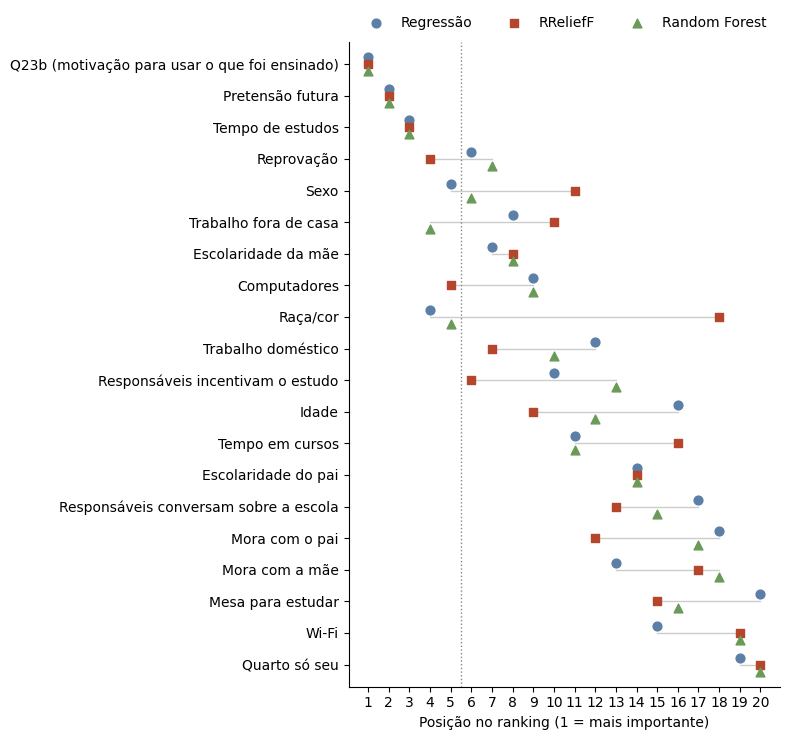

In [31]:
g = comp.sort_values('Posição média', ascending=False).reset_index(drop=True)
pos_y = np.arange(len(g))
fig, ax = plt.subplots(figsize=(8, 7.5))
estilos = [('Posição (regressão)', 'o', '#5b7fa6', 'Regressão', 0.22),
           ('Posição (RReliefF)', 's', '#b5452b', 'RReliefF', 0.0),
           ('Posição (Random Forest)', '^', '#6a9a58', 'Random Forest', -0.22)]
for i, r in g.iterrows():
    pos = [r[c] for c, *_ in estilos]
    ax.plot([min(pos), max(pos)], [pos_y[i], pos_y[i]], color='#cccccc', linewidth=1, zorder=1)
for col, marc, cor, rot, desl in estilos:
    ax.scatter(g[col], pos_y + desl, marker=marc, color=cor, s=40, label=rot, zorder=3)
ax.set_yticks(pos_y)
ax.set_yticklabels(g['Atributo'])
ax.axvline(TOP + 0.5, color='#888888', linestyle=':', linewidth=1)
ax.set_xlabel('Posição no ranking (1 = mais importante)')
ax.set_xticks(range(1, len(ATRIBUTOS) + 1))
ax.set_ylim(-0.7, len(g) - 0.3)
ax.legend(frameon=False, loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=3)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig(PASTA + 'figura_comparacao_metodos.png', dpi=300)
plt.show()

## Exportação

In [32]:
with pd.ExcelWriter(PASTA + 'tabelas_comparacao_metodos.xlsx') as xw:
    for nome, t in TABELAS.items():
        t.to_excel(xw, sheet_name=nome[:31], index=False)
print('Tabelas salvas em', PASTA + 'tabelas_comparacao_metodos.xlsx')

Tabelas salvas em /content/drive/MyDrive/dissertacao/tabelas_comparacao_metodos.xlsx
